Maintenant, nous passons réellement au premier traitement scientifique du projet :
T0 → S_DA, S_BI, S_DS, S_IA → compétences → lacunes → diagnostic initial.
Mais il y a une règle capitale : nous ne devons pas deviner les bonnes réponses aux 20 questions.
Le prochain notebook devra donc commencer par :
1. charger T0_nettoye.csv ;
2. charger dictionnaire_questions_T0.csv ;
3. définir/valider le corrigé officiel des 20 questions ;
4. vérifier les réponses observées ;
5. calculer séparément :

S_{DA},S_{BI}, S_{DS}, S_{IA}
avec :\[
S_d=\frac{\text{nombre de réponses correctes du domaine }d}{5}\times100
\]


6. produire les scores possibles : 0, 20, 40, 60, 80, 100 ;
7. identifier les questions réussies et échouées ;
8. construire le diagnostic initial, sans encore transformer ces scores en niveau Débutant/Intermédiaire/Avancé tant que la règle de niveau n'est pas formellement fixée.

# 02 — Diagnostic initial T0

Ce notebook construit le diagnostic initial à partir du test T0.

Objectifs :

1. charger les données T0 nettoyées ;
2. contrôler les 20 questions ;
3. inventorier les modalités de réponse réellement observées ;
4. établir et valider le corrigé officiel ;
5. calculer séparément S_DA, S_BI, S_DS et S_IA ;
6. identifier les acquis et les lacunes observés ;
7. analyser les distributions et les questions ;
8. construire le diagnostic initial de chaque apprenant.

Règles méthodologiques :

- Q1–Q5 : Data Analysis ;
- Q6–Q10 : Business Intelligence ;
- Q11–Q15 : Data Science ;
- Q16–Q20 : Intelligence Artificielle ;
- chaque domaine comporte exactement cinq items ;
- aucun score global n'est construit ;
- aucun niveau Débutant / Intermédiaire / Avancé n'est attribué automatiquement ;
- aucun parcours n'est recommandé dans ce notebook ;
- les scores T0 sont considérés comme des indicateurs diagnostiques à granularité limitée.

# Cellule 1 — Imports et dossiers

In [1]:
# ============================================================
# CELLULE 1 — Imports et configuration
# ============================================================

from pathlib import Path
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)


def trouver_racine_projet():

    candidats = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent
    ]

    for racine in candidats:

        if (
            racine
            / "outputs"
            / "01_nettoyage"
        ).exists():

            return racine.resolve()

    raise FileNotFoundError(
        "Impossible de trouver outputs/01_nettoyage/"
    )


PROJECT_ROOT = trouver_racine_projet()

INPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "01_nettoyage"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "02_diagnostic_T0"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("PROJECT_ROOT :", PROJECT_ROOT)
print("INPUT_DIR    :", INPUT_DIR)
print("OUTPUT_DIR   :", OUTPUT_DIR)

PROJECT_ROOT : /home/andrycomputer/Documents/Model-eval-pers-elearning
INPUT_DIR    : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/01_nettoyage
OUTPUT_DIR   : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/02_diagnostic_T0


# Cellule 2 — Charger T0 et D1

In [2]:
# ============================================================
# CELLULE 2 — Chargement
# ============================================================

T0_FILE = (
    INPUT_DIR
    / "T0_nettoye.csv"
)

DICT_FILE = (
    INPUT_DIR
    / "dictionnaire_questions_T0.csv"
)

D1_FILE = (
    INPUT_DIR
    / "D1_profils_nettoyes.csv"
)


for fichier in [
    T0_FILE,
    DICT_FILE
]:

    if not fichier.exists():

        raise FileNotFoundError(
            fichier
        )


t0 = pd.read_csv(
    T0_FILE
)

dict_t0 = pd.read_csv(
    DICT_FILE
)


d1 = (
    pd.read_csv(D1_FILE)
    if D1_FILE.exists()
    else None
)


print(
    "T0 :",
    t0.shape
)

print(
    "Dictionnaire :",
    dict_t0.shape
)

print(
    "D1 disponible :",
    d1 is not None
)


display(
    dict_t0
)

T0 : (305, 29)
Dictionnaire : (20, 3)
D1 disponible : True


,Q_NUM,DOMAINE,QUESTION
0,1,DA,Q1 - Resume ventes Excel
1,2,DA,Q2 - Import CSV Excel
2,3,DA,Q3 - Modele donnees Excel
3,4,DA,Q4 - Mauvaise pratique visu Excel
4,5,DA,Q5 - 2e grande valeur Excel
5,6,BI,Q6 - Mesure vs Colonne DAX
6,7,BI,Q7 - CA annee precedente DAX
7,8,BI,Q8 - Vue Modele Power BI
8,9,BI,Q9 - Acces directeurs regionaux
9,10,BI,Q10 - 12 commerciaux 3 indicateurs


# Cellule 3 — Vérifier la structure scientifique de T0

In [3]:
# ============================================================
# CELLULE 3 — Validation structurelle
# ============================================================

COL_ID = "_ID_NORM"


if COL_ID not in t0.columns:

    raise ValueError(
        "_ID_NORM absent de T0"
    )


if t0[COL_ID].isna().any():

    raise ValueError(
        "Des IDs manquent encore dans T0 nettoyé."
    )


if t0[COL_ID].duplicated().any():

    raise ValueError(
        "IDs dupliqués dans T0."
    )


# Le notebook précédent peut avoir utilisé
# QUESTION ou COLONNE comme nom.
if "QUESTION" in dict_t0.columns:

    COL_QUESTION = "QUESTION"

elif "COLONNE" in dict_t0.columns:

    COL_QUESTION = "COLONNE"

else:

    raise ValueError(
        "Le dictionnaire doit contenir QUESTION ou COLONNE."
    )


dict_t0["Q_NUM"] = pd.to_numeric(
    dict_t0["Q_NUM"],
    errors="raise"
).astype(int)


dict_t0["DOMAINE"] = (
    dict_t0["DOMAINE"]
    .astype(str)
    .str.strip()
    .str.upper()
)


dict_t0 = (
    dict_t0
    .sort_values("Q_NUM")
    .reset_index(drop=True)
)


questions = (
    dict_t0[
        COL_QUESTION
    ]
    .tolist()
)


questions_absentes = [
    q
    for q in questions
    if q not in t0.columns
]


if questions_absentes:

    raise ValueError(
        f"Questions absentes : {questions_absentes}"
    )


controle_domaines = (

    dict_t0
    .groupby("DOMAINE")
    ["Q_NUM"]
    .count()

    .reindex(
        ["DA", "BI", "DS", "IA"]
    )

)


display(
    controle_domaines
    .rename("N_ITEMS")
    .to_frame()
)


if not (
    controle_domaines == 5
).all():

    raise ValueError(
        "Chaque domaine doit contenir exactement 5 items."
    )


print(
    "✅ Structure T0 correcte"
)

print(
    "Apprenants :",
    len(t0)
)

print(
    "Questions :",
    len(questions)
)

,N_ITEMS
DOMAINE,
DA,5
BI,5
DS,5
IA,5


✅ Structure T0 correcte
Apprenants : 305
Questions : 20


#  Cellule 4 — Normalisation des réponses

In [4]:
# ============================================================
# CELLULE 4 — Normalisation
# ============================================================

def normaliser_texte(valeur):

    if pd.isna(valeur):
        return pd.NA

    texte = str(
        valeur
    ).strip()

    texte = re.sub(
        r"\s+",
        " ",
        texte
    )

    if texte.upper() in {
        "",
        "NAN",
        "NONE",
        "NULL",
        "<NA>"
    }:

        return pd.NA

    return texte


def cle_comparaison(valeur):

    if pd.isna(valeur):
        return pd.NA

    texte = unicodedata.normalize(
        "NFKD",
        str(valeur)
    )

    texte = "".join(
        c for c in texte
        if not unicodedata.combining(c)
    )

    texte = re.sub(
        r"\s+",
        " ",
        texte
    )

    return (
        texte
        .strip()
        .casefold()
    )


print(
    "✅ Fonctions prêtes"
)

✅ Fonctions prêtes


# Cellule 5 — Inventaire des réponses observées
Cette cellule est importante : elle nous montre toutes les options réellement présentes pour chaque QCM.

In [5]:
# ============================================================
# CELLULE 5 — Modalités de réponse observées
# ============================================================

inventaire = []


for _, row in dict_t0.iterrows():

    q_num = int(
        row["Q_NUM"]
    )

    domaine = (
        row["DOMAINE"]
    )

    question = (
        row[
            COL_QUESTION
        ]
    )


    reponses = (
        t0[question]
        .map(
            normaliser_texte
        )
    )


    valeurs = sorted(
        reponses
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )


    inventaire.append({

        "Q_NUM":
            q_num,

        "DOMAINE":
            domaine,

        "QUESTION":
            question,

        "N_MODALITES_OBSERVEES":
            len(valeurs),

        "MODALITES_OBSERVEES":
            " || ".join(
                valeurs
            )

    })


inventaire_modalites = (
    pd.DataFrame(
        inventaire
    )
)


display(
    inventaire_modalites
)


inventaire_modalites.to_csv(

    OUTPUT_DIR
    / "inventaire_modalites_T0.csv",

    index=False,

    encoding="utf-8-sig"

)

,Q_NUM,DOMAINE,QUESTION,N_MODALITES_OBSERVEES,MODALITES_OBSERVEES
0,1,DA,Q1 - Resume ventes Excel,5,A. Filtre automatique || B. Tableau croise dyn...
1,2,DA,Q2 - Import CSV Excel,5,A. Macros VBA manuelles || B. Copier-coller ma...
2,3,DA,Q3 - Modele donnees Excel,5,A. Fusionner dans une feuille || B. TCD simple...
3,4,DA,Q4 - Mauvaise pratique visu Excel,5,A. Courbes pour tendances temporelles || B. Li...
4,5,DA,Q5 - 2e grande valeur Excel,5,A. NB.SI(plage;sup0) || B. GRANDE.VALEUR(plage...
5,6,BI,Q6 - Mesure vs Colonne DAX,5,A. Aucune difference || B. Colonne calculee pl...
6,7,BI,Q7 - CA annee precedente DAX,5,A. DATEADD(-12 MONTH) || B. CALCULATE(SUM SAME...
7,8,BI,Q8 - Vue Modele Power BI,5,A. Creer visuels interactifs || B. Publier sur...
8,9,BI,Q9 - Acces directeurs regionaux,5,A. Filtrer manuellement les visuels || B. Row-...
9,10,BI,Q10 - 12 commerciaux 3 indicateurs,5,A. Histogramme empile || B. Graphique en secte...


# Cellule 6 — Générer le corrigé à valider

corrige_T0_valide.csv :est corriger et remplir mnuelement le REPONSE_CORRECTE et l competence

In [6]:
# ============================================================
# CELLULE 6 — Template du corrigé officiel
# ============================================================

CORRIGE_TEMPLATE = (
    OUTPUT_DIR
    / "corrige_T0_a_valider.csv"
)


CORRIGE_VALIDE = (
    OUTPUT_DIR
    / "corrige_T0_valide.csv"
)


if not CORRIGE_TEMPLATE.exists():

    corrige_template = (
        inventaire_modalites
        .copy()
    )


    corrige_template[
        "REPONSE_CORRECTE"
    ] = ""


    corrige_template[
        "COMPETENCE"
    ] = ""


    corrige_template[
        "JUSTIFICATION_COURTE"
    ] = ""


    corrige_template.to_csv(

        CORRIGE_TEMPLATE,

        index=False,

        encoding="utf-8-sig"

    )


    print(
        "✅ Créé :",
        CORRIGE_TEMPLATE
    )

else:

    print(
        "ℹ️ Template déjà existant"
    )

ℹ️ Template déjà existant


In [7]:
# ============================================================
# CELLULE 6B — Validation et création du corrigé final
# ============================================================

corrige_temp = pd.read_csv(
    CORRIGE_TEMPLATE
)


# Vérifications minimales
if len(corrige_temp) != 20:
    raise ValueError(
        f"20 questions attendues, {len(corrige_temp)} trouvées."
    )


if corrige_temp["Q_NUM"].duplicated().any():
    raise ValueError(
        "Q_NUM dupliqué dans le corrigé."
    )


if (
    corrige_temp["REPONSE_CORRECTE"]
    .isna()
    .any()
):
    raise ValueError(
        "Certaines réponses correctes ne sont pas renseignées."
    )


if (
    corrige_temp["REPONSE_CORRECTE"]
    .astype(str)
    .str.strip()
    .eq("")
    .any()
):
    raise ValueError(
        "Certaines réponses correctes sont vides."
    )


# Vérification 5 questions par domaine
controle_domaines_corrige = (
    corrige_temp
    .groupby("DOMAINE")
    ["Q_NUM"]
    .count()
)


print("Questions par domaine :")
display(
    controle_domaines_corrige
    .rename("N")
    .to_frame()
)


if not (
    controle_domaines_corrige
    .reindex(["DA", "BI", "DS", "IA"])
    .eq(5)
    .all()
):
    raise ValueError(
        "Chaque domaine doit contenir exactement 5 questions."
    )


# Création du corrigé officiellement utilisé
corrige_temp.to_csv(
    CORRIGE_VALIDE,
    index=False,
    encoding="utf-8-sig"
)


print("✅ Corrigé validé")
print("Fichier créé :", CORRIGE_VALIDE)

Questions par domaine :


,N
DOMAINE,
BI,5
DA,5
DS,5
IA,5


✅ Corrigé validé
Fichier créé : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/02_diagnostic_T0/corrige_T0_valide.csv


# Cellule 7 — Valider le corrigé

In [8]:
# ============================================================
# CELLULE 7 — Validation stricte du corrigé
# ============================================================

if not CORRIGE_VALIDE.exists():

    raise FileNotFoundError(

        "corrige_T0_valide.csv absent.\n"

        "Remplissez d'abord "
        "corrige_T0_a_valider.csv."
    )


corrige = pd.read_csv(
    CORRIGE_VALIDE
)


colonnes_obligatoires = {

    "Q_NUM",
    "DOMAINE",
    "QUESTION",
    "REPONSE_CORRECTE"

}


manquantes = (
    colonnes_obligatoires
    - set(corrige.columns)
)


if manquantes:

    raise ValueError(
        f"Colonnes manquantes : {manquantes}"
    )


corrige["Q_NUM"] = pd.to_numeric(
    corrige["Q_NUM"],
    errors="raise"
).astype(int)


corrige["REPONSE_CORRECTE"] = (

    corrige[
        "REPONSE_CORRECTE"
    ]

    .map(
        normaliser_texte
    )

)


if len(corrige) != 20:

    raise ValueError(
        "Le corrigé doit contenir exactement 20 lignes."
    )


if corrige["Q_NUM"].duplicated().any():

    raise ValueError(
        "Q_NUM dupliqué dans le corrigé."
    )


if (
    corrige[
        "REPONSE_CORRECTE"
    ]
    .isna()
    .any()
):

    q_manquantes = (

        corrige.loc[
            corrige[
                "REPONSE_CORRECTE"
            ].isna(),
            "Q_NUM"
        ]

        .tolist()

    )

    raise ValueError(
        f"Réponses correctes manquantes : {q_manquantes}"
    )


print(
    "✅ Corrigé complet : 20/20"
)

✅ Corrigé complet : 20/20


# Cellule 8 — Vérifier que les bonnes réponses existent réellement

In [9]:
# ============================================================
# CELLULE 8 — Validation des options du corrigé
# ============================================================

def extraire_option(valeur):
    """
    Extrait la lettre A, B, C, D ou E.

    Fonctionne avec :
    - "B"
    - "B."
    - "B. Tableau croise dynamique"
    - "B) Tableau croise dynamique"
    """

    if pd.isna(valeur):
        return pd.NA

    texte = str(valeur).strip().upper()

    # Cas : lettre seule
    if texte in {"A", "B", "C", "D", "E"}:
        return texte

    # Cas : "A. ...", "B) ...", etc.
    match = re.match(
        r"^\s*([A-E])(?:\s*[\.\)\-:]|\s+)",
        texte
    )

    if match:
        return match.group(1)

    return pd.NA


# Extraction de l'option correcte depuis le corrigé
corrige["OPTION_CORRECTE"] = (
    corrige["REPONSE_CORRECTE"]
    .map(extraire_option)
)


# Vérification
if corrige["OPTION_CORRECTE"].isna().any():

    problemes = corrige.loc[
        corrige["OPTION_CORRECTE"].isna(),
        [
            "Q_NUM",
            "QUESTION",
            "REPONSE_CORRECTE"
        ]
    ]

    display(problemes)

    raise ValueError(
        "Certaines réponses correctes ne correspondent pas "
        "à une option A, B, C, D ou E."
    )


print("Options correctes détectées :")

display(
    corrige[
        [
            "Q_NUM",
            "DOMAINE",
            "REPONSE_CORRECTE",
            "OPTION_CORRECTE"
        ]
    ]
)


# Vérifier que l'option correcte existe réellement
# parmi les réponses observées
alertes = []

for _, row in corrige.iterrows():

    question = row["QUESTION"]

    options_observees = set(
        t0[question]
        .dropna()
        .map(extraire_option)
        .dropna()
        .unique()
    )

    option_correcte = row["OPTION_CORRECTE"]

    if option_correcte not in options_observees:

        alertes.append({
            "Q_NUM": row["Q_NUM"],
            "QUESTION": question,
            "OPTION_CORRECTE": option_correcte,
            "OPTIONS_OBSERVEES": sorted(options_observees)
        })


if alertes:

    display(
        pd.DataFrame(alertes)
    )

    raise ValueError(
        "Certaines options correctes ne sont pas observées "
        "dans les données."
    )

else:

    print(
        "✅ Les 20 options correctes sont valides."
    )

Options correctes détectées :


,Q_NUM,DOMAINE,REPONSE_CORRECTE,OPTION_CORRECTE
0,1,DA,B,B
1,2,DA,D,D
2,3,DA,C,C
3,4,DA,D,D
4,5,DA,B,B
5,6,BI,C,C
6,7,BI,B,B
7,8,BI,D,D
8,9,BI,B,B
9,10,BI,D,D


✅ Les 20 options correctes sont valides.


# Cellule 9 — Construire la table T0 au format long

In [10]:
# ============================================================
# CELLULE 9 — Format long + scoring par lettre d'option
# ============================================================

colonnes_corrige = [
    "Q_NUM",
    "DOMAINE",
    "QUESTION",
    "REPONSE_CORRECTE",
    "OPTION_CORRECTE"
]


if "COMPETENCE" in corrige.columns:
    colonnes_corrige.append(
        "COMPETENCE"
    )


map_questions = (
    corrige[colonnes_corrige]
    .copy()
)


if "COMPETENCE" not in map_questions.columns:

    map_questions["COMPETENCE"] = pd.NA


question_cols = (
    map_questions
    .sort_values("Q_NUM")
    ["QUESTION"]
    .tolist()
)


# Passage au format long
long_t0 = (
    t0[
        [COL_ID]
        + question_cols
    ]

    .melt(
        id_vars=[COL_ID],
        value_vars=question_cols,
        var_name="QUESTION",
        value_name="REPONSE"
    )
)


# Ajout du domaine, corrigé, compétence...
long_t0 = long_t0.merge(
    map_questions,
    on="QUESTION",
    how="left",
    validate="many_to_one"
)


# Normalisation de la réponse
long_t0["REPONSE"] = (
    long_t0["REPONSE"]
    .map(normaliser_texte)
)


# ------------------------------------------------------------
# Réponse explicite "Je ne sais pas"
# ------------------------------------------------------------

long_t0[
    "REPONSE_JE_NE_SAIS_PAS"
] = (
    long_t0["REPONSE"]
    .map(cle_comparaison)
    .fillna("")
    .str.contains(
        "je ne sais pas",
        regex=False
    )
)


# Réponse manquante
long_t0["REPONSE_MANQUANTE"] = (
    long_t0["REPONSE"]
    .isna()
)


# Extraction de la lettre choisie par l'apprenant
long_t0["OPTION_REPONSE"] = (
    long_t0["REPONSE"]
    .map(extraire_option)
)


# Score binaire
long_t0["CORRECT"] = (
    long_t0["OPTION_REPONSE"]
    .notna()

    &

    long_t0["OPTION_REPONSE"]
    .eq(
        long_t0["OPTION_CORRECTE"]
    )
).astype(int)


# Tri
long_t0 = (
    long_t0
    .sort_values(
        [
            COL_ID,
            "Q_NUM"
        ]
    )
    .reset_index(drop=True)
)


print(
    "Nombre de lignes :",
    len(long_t0)
)

print(
    "Nombre attendu :",
    len(t0) * 20
)


# Contrôle rapide
display(
    long_t0[
        [
            COL_ID,
            "Q_NUM",
            "DOMAINE",
            "OPTION_REPONSE",
            "OPTION_CORRECTE",
            "REPONSE_JE_NE_SAIS_PAS",
            "CORRECT"
        ]
    ].head(30)
)

Nombre de lignes : 6100
Nombre attendu : 6100


,_ID_NORM,Q_NUM,DOMAINE,OPTION_REPONSE,OPTION_CORRECTE,REPONSE_JE_NE_SAIS_PAS,CORRECT
0,DIEG2026-001,1,DA,A,B,False,0
1,DIEG2026-001,2,DA,C,D,False,0
2,DIEG2026-001,3,DA,D,C,False,0
3,DIEG2026-001,4,DA,B,D,False,0
4,DIEG2026-001,5,DA,D,B,False,0
5,DIEG2026-001,6,BI,C,C,False,1
6,DIEG2026-001,7,BI,B,B,False,1
7,DIEG2026-001,8,BI,D,D,False,1
8,DIEG2026-001,9,BI,C,B,False,0
9,DIEG2026-001,10,BI,D,D,False,1


In [11]:
# ============================================================
# CELLULE 9B — Contrôle technique du scoring
# ============================================================

print("Nombre de lignes :", len(long_t0))
print("Nombre attendu    :", len(t0) * 20)

print(
    "Options non reconnues :",
    long_t0["OPTION_REPONSE"].isna().sum()
)

print(
    "Réponses manquantes :",
    long_t0["REPONSE_MANQUANTE"].sum()
)

print(
    "Réponses « Je ne sais pas » :",
    long_t0["REPONSE_JE_NE_SAIS_PAS"].sum()
)

print("\nDistribution des options :")

display(
    long_t0["OPTION_REPONSE"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("N")
    .to_frame()
)

print("\nTaux global de réponses correctes :")

print(
    round(
        long_t0["CORRECT"].mean() * 100,
        2
    ),
    "%"
)

Nombre de lignes : 6100
Nombre attendu    : 6100
Options non reconnues : 0
Réponses manquantes : 0
Réponses « Je ne sais pas » : 2555

Distribution des options :


,N
OPTION_REPONSE,
A,633
B,1036
C,1033
D,843
E,2555



Taux global de réponses correctes :
22.89 %


# Cellule 10 — Contrôler les 5 items par domaine

In [12]:
# ============================================================
# CELLULE 10 — Contrôle du scoring
# ============================================================

controle = (

    long_t0

    .groupby(
        [
            COL_ID,
            "DOMAINE"
        ]
    )

    .size()

    .rename(
        "N_ITEMS"
    )

    .reset_index()

)


display(
    controle[
        "N_ITEMS"
    ]
    .value_counts()
)


if not (
    controle[
        "N_ITEMS"
    ] == 5
).all():

    raise ValueError(
        "Un domaine ne possède pas exactement 5 items."
    )


print(
    "✅ 5 items par domaine pour chaque apprenant"
)

N_ITEMS
5    1220
Name: count, dtype: int64

✅ 5 items par domaine pour chaque apprenant


# Cellule 11 — Calculer les quatre scores

DA, Q1–Q5 : 0/5 correct → S_DA = 0
BI, Q6–Q10 : 4/5 correct → S_BI = 80
DS, Q11–Q15 : 1/5 correct → S_DS = 20
IA, Q16–Q20 : 1/5 correct → S_IA = 20

In [13]:
# ============================================================
# CELLULE 11 — Calcul de S_DA, S_BI, S_DS et S_IA
# ============================================================

scores_long = (
    long_t0

    .groupby(
        [
            COL_ID,
            "DOMAINE"
        ],
        as_index=False
    )

    .agg(

        N_CORRECTES=(
            "CORRECT",
            "sum"
        ),

        N_REPONSES=(
            "REPONSE_MANQUANTE",
            lambda x: int(
                (~x).sum()
            )
        ),

        N_MANQUANTES=(
            "REPONSE_MANQUANTE",
            "sum"
        )

    )
)


# 5 questions par domaine
scores_long["SCORE"] = (
    scores_long["N_CORRECTES"]
    / 5
    * 100
)


scores_long["TAUX_COMPLETUDE"] = (
    scores_long["N_REPONSES"]
    / 5
    * 100
)


# Format large
scores_wide = (
    scores_long

    .pivot(
        index=COL_ID,
        columns="DOMAINE",
        values="SCORE"
    )

    .reset_index()

    .rename(
        columns={
            "DA": "S_DA",
            "BI": "S_BI",
            "DS": "S_DS",
            "IA": "S_IA"
        }
    )
)


# Retirer le nom d'axe "DOMAINE" affiché au-dessus des colonnes
scores_wide.columns.name = None


scores_wide = scores_wide[
    [
        COL_ID,
        "S_DA",
        "S_BI",
        "S_DS",
        "S_IA"
    ]
]


print(
    "Nombre d'apprenants :",
    len(scores_wide)
)


display(
    scores_wide.head(10)
)

Nombre d'apprenants : 305


,_ID_NORM,S_DA,S_BI,S_DS,S_IA
0,DIEG2026-001,0.0,80.0,20.0,20.0
1,DIEG2026-002,20.0,40.0,0.0,40.0
2,DIEG2026-003,0.0,0.0,0.0,0.0
3,DIEG2026-004,80.0,60.0,40.0,20.0
4,DIEG2026-005,60.0,60.0,40.0,80.0
5,DIEG2026-006,0.0,0.0,0.0,20.0
6,DIEG2026-007,40.0,20.0,80.0,20.0
7,DIEG2026-008,20.0,0.0,20.0,40.0
8,DIEG2026-009,60.0,40.0,20.0,20.0
9,DIEG2026-011,20.0,0.0,60.0,0.0


# Cellule 12 — Vérifier les scores

In [14]:
# ============================================================
# CELLULE 12 — Validation des scores
# ============================================================

VALEURS_AUTORISEES = {
    0,
    20,
    40,
    60,
    80,
    100
}


for col in [
    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"
]:

    valeurs = set(

        scores_wide[col]
        .dropna()
        .unique()

    )


    print(
        col,
        sorted(valeurs)
    )


    if not valeurs.issubset(
        VALEURS_AUTORISEES
    ):

        raise ValueError(
            f"Valeurs anormales dans {col}"
        )


print(
    "✅ Scores valides"
)

S_DA [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
S_BI [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
S_DS [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
S_IA [0.0, 20.0, 40.0, 60.0, 80.0, 100.0]
✅ Scores valides


# Cellule 13 — Statistiques des scores

In [15]:
# ============================================================
# CELLULE 13 — Statistiques descriptives
# ============================================================

score_cols = [
    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"
]


stats_scores = (

    scores_wide[
        score_cols
    ]

    .describe()

    .T

)


display(
    stats_scores
)

,count,mean,std,min,25%,50%,75%,max
S_DA,305.0,27.606557,27.953956,0.0,0.0,20.0,40.0,100.0
S_BI,305.0,21.573770,27.244301,0.0,0.0,20.0,40.0,100.0
S_DS,305.0,21.508197,27.416514,0.0,0.0,20.0,40.0,100.0
S_IA,305.0,20.852459,27.967225,0.0,0.0,0.0,40.0,100.0


In [16]:
# ============================================================
# CELLULE 13B — Distribution détaillée des scores par domaine
# ============================================================

distribution_scores = []

for col in [
    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"
]:

    temp = (
        scores_wide[col]
        .value_counts()
        .reindex(
            [0, 20, 40, 60, 80, 100],
            fill_value=0
        )
        .rename("N")
        .reset_index()
        .rename(
            columns={
                col: "SCORE"
            }
        )
    )

    temp["DOMAINE"] = col.replace("S_", "")

    temp["POURCENTAGE"] = (
        temp["N"]
        / len(scores_wide)
        * 100
    )

    distribution_scores.append(temp)


distribution_scores = pd.concat(
    distribution_scores,
    ignore_index=True
)


display(
    distribution_scores[
        [
            "DOMAINE",
            "SCORE",
            "N",
            "POURCENTAGE"
        ]
    ]
)

,DOMAINE,SCORE,N,POURCENTAGE
0,DA,0,95,31.147541
1,DA,20,102,33.442623
2,DA,40,53,17.377049
3,DA,60,22,7.213115
4,DA,80,18,5.901639
5,DA,100,15,4.918033
6,BI,0,146,47.868852
7,BI,20,68,22.295082
8,BI,40,46,15.081967
9,BI,60,23,7.540984


In [17]:
# ============================================================
# CELLULE 13C — Indicateurs synthétiques T0
# ============================================================

resume_scores = []

for col in [
    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"
]:

    resume_scores.append({

        "DOMAINE":
            col.replace("S_", ""),

        "N":
            len(scores_wide),

        "MOYENNE":
            scores_wide[col].mean(),

        "MEDIANE":
            scores_wide[col].median(),

        "ECART_TYPE":
            scores_wide[col].std(),

        "N_SCORE_0":
            (scores_wide[col] == 0).sum(),

        "PCT_SCORE_0":
            (scores_wide[col] == 0).mean() * 100,

        "N_SCORE_100":
            (scores_wide[col] == 100).sum(),

        "PCT_SCORE_100":
            (scores_wide[col] == 100).mean() * 100,

        "N_SCORE_GE_60":
            (scores_wide[col] >= 60).sum(),

        "PCT_SCORE_GE_60":
            (scores_wide[col] >= 60).mean() * 100

    })


resume_scores = pd.DataFrame(
    resume_scores
)


display(resume_scores)

,DOMAINE,N,MOYENNE,MEDIANE,ECART_TYPE,N_SCORE_0,PCT_SCORE_0,N_SCORE_100,PCT_SCORE_100,N_SCORE_GE_60,PCT_SCORE_GE_60
0,DA,305,27.606557,20.0,27.953956,95,31.147541,15,4.918033,55,18.032787
1,BI,305,21.573770,20.0,27.244301,146,47.868852,12,3.934426,45,14.754098
2,DS,305,21.508197,20.0,27.416514,141,46.229508,15,4.918033,41,13.442623
3,IA,305,20.852459,0.0,27.967225,155,50.819672,12,3.934426,42,13.770492


# Cellule 14 — Difficulté / taux de réussite des 20 items

In [18]:
# ============================================================
# CELLULE 14 — Analyse par item
# ============================================================

stats_items = (

    long_t0

    .groupby(
        [
            "Q_NUM",
            "DOMAINE",
            "QUESTION"
        ],
        as_index=False
    )

    .agg(

        N_APPRENANTS=(
            COL_ID,
            "nunique"
        ),

        N_REPONSES=(
            "REPONSE_MANQUANTE",
            lambda x:
                int(
                    (~x).sum()
                )
        ),

        N_MANQUANTES=(
            "REPONSE_MANQUANTE",
            "sum"
        ),

        N_CORRECTES=(
            "CORRECT",
            "sum"
        )

    )

)


stats_items[
    "TAUX_REUSSITE"
] = (

    stats_items[
        "N_CORRECTES"
    ]

    / stats_items[
        "N_APPRENANTS"
    ]

    * 100

)


stats_items[
    "TAUX_REPONSE"
] = (

    stats_items[
        "N_REPONSES"
    ]

    / stats_items[
        "N_APPRENANTS"
    ]

    * 100

)


display(
    stats_items
)

,Q_NUM,DOMAINE,QUESTION,N_APPRENANTS,N_REPONSES,N_MANQUANTES,N_CORRECTES,TAUX_REUSSITE,TAUX_REPONSE
0,1,DA,Q1 - Resume ventes Excel,305,305,0,110,36.065574,100.0
1,2,DA,Q2 - Import CSV Excel,305,305,0,57,18.688525,100.0
2,3,DA,Q3 - Modele donnees Excel,305,305,0,77,25.245902,100.0
3,4,DA,Q4 - Mauvaise pratique visu Excel,305,305,0,87,28.524590,100.0
4,5,DA,Q5 - 2e grande valeur Excel,305,305,0,90,29.508197,100.0
5,6,BI,Q6 - Mesure vs Colonne DAX,305,305,0,87,28.524590,100.0
6,7,BI,Q7 - CA annee precedente DAX,305,305,0,67,21.967213,100.0
7,8,BI,Q8 - Vue Modele Power BI,305,305,0,66,21.639344,100.0
8,9,BI,Q9 - Acces directeurs regionaux,305,305,0,61,20.000000,100.0
9,10,BI,Q10 - 12 commerciaux 3 indicateurs,305,305,0,48,15.737705,100.0


# Cellule 14B — KR-20

In [19]:
# ============================================================
# CELLULE 14B — Fiabilité interne KR-20 par domaine
# ============================================================

def calculer_kr20(df_items):

    k = df_items.shape[1]

    if k < 2:
        return np.nan

    p = df_items.mean(
        axis=0
    )

    q = 1 - p

    score_total = (
        df_items.sum(axis=1)
    )

    variance_total = (
        score_total.var(ddof=1)
    )

    if (
        pd.isna(variance_total)
        or variance_total == 0
    ):
        return np.nan

    return (
        k / (k - 1)
        *
        (
            1
            -
            (
                (p * q).sum()
                / variance_total
            )
        )
    )


resultats_kr20 = []


for domaine in [
    "DA",
    "BI",
    "DS",
    "IA"
]:

    temp = (
        long_t0[
            long_t0[
                "DOMAINE"
            ] == domaine
        ]

        .pivot(
            index=COL_ID,
            columns="Q_NUM",
            values="CORRECT"
        )
    )

    assert temp.shape[1] == 5

    resultats_kr20.append({
        "DOMAINE":
            domaine,

        "N_APPRENANTS":
            temp.shape[0],

        "N_ITEMS":
            temp.shape[1],

        "KR20":
            calculer_kr20(temp)
    })


KR20_T0 = pd.DataFrame(
    resultats_kr20
)


display(KR20_T0)

,DOMAINE,N_APPRENANTS,N_ITEMS,KR20
0,DA,305,5,0.620921
1,BI,305,5,0.685856
2,DS,305,5,0.700129
3,IA,305,5,0.729336


# Cellule 15 — Acquis et lacunes observés

In [20]:
# ============================================================
# CELLULE 15 — Diagnostic item par item
# ============================================================

long_t0[
    "LIBELLE_DIAGNOSTIQUE"
] = (

    long_t0[
        "COMPETENCE"
    ]

    .fillna(
        long_t0[
            "QUESTION"
        ]
    )

)


long_t0[
    "ACQUIS_OBSERVE"
] = np.where(

    long_t0[
        "CORRECT"
    ].eq(1),

    long_t0[
        "LIBELLE_DIAGNOSTIQUE"
    ],

    pd.NA

)


long_t0[
    "LACUNE_OBSERVEE"
] = np.where(

    long_t0[
        "CORRECT"
    ].eq(0),

    long_t0[
        "LIBELLE_DIAGNOSTIQUE"
    ],

    pd.NA

)


# Distinguer les absences de réponse
mask_non_reponse = (

    long_t0[
        "REPONSE_MANQUANTE"
    ]

)


long_t0.loc[
    mask_non_reponse,
    "LACUNE_OBSERVEE"
] = (

    "NON-REPONSE — "

    + long_t0.loc[
        mask_non_reponse,
        "LIBELLE_DIAGNOSTIQUE"
    ].astype(str)

)

#  Cellule 16 — Résumer acquis/lacunes par apprenant

In [21]:
# ============================================================
# CELLULE 16 — Synthèse par apprenant
# ============================================================

def joindre_uniques(serie):

    valeurs = [

        str(x)

        for x in serie.dropna()

    ]

    return " | ".join(
        dict.fromkeys(
            valeurs
        )
    )


diagnostic_domaines = (

    long_t0

    .groupby(
        [
            COL_ID,
            "DOMAINE"
        ],
        as_index=False
    )

    .agg(

        ACQUIS_OBSERVES=(
            "ACQUIS_OBSERVE",
            joindre_uniques
        ),

        LACUNES_OBSERVEES=(
            "LACUNE_OBSERVEE",
            joindre_uniques
        )

    )

)


acquis = (

    diagnostic_domaines

    .pivot(
        index=COL_ID,
        columns="DOMAINE",
        values="ACQUIS_OBSERVES"
    )

    .add_prefix(
        "ACQUIS_"
    )

    .reset_index()

)


lacunes = (

    diagnostic_domaines

    .pivot(
        index=COL_ID,
        columns="DOMAINE",
        values="LACUNES_OBSERVEES"
    )

    .add_prefix(
        "LACUNES_"
    )

    .reset_index()

)


diagnostic_items = (

    acquis

    .merge(

        lacunes,

        on=COL_ID,

        how="outer",

        validate="one_to_one"

    )

)


display(
    diagnostic_items.head()
)

DOMAINE,_ID_NORM,ACQUIS_BI,ACQUIS_DA,ACQUIS_DS,ACQUIS_IA,LACUNES_BI,LACUNES_DA,LACUNES_DS,LACUNES_IA
0,DIEG2026-001,DAX (mesures vs colonnes calculées) | DAX (Tim...,,Déploiement de modèles ML,IA générative - RAG,Sécurité Power BI (RLS),Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - emb...
1,DIEG2026-002,DAX (mesures vs colonnes calculées) | Sécurité...,Modélisation de données (Power Pivot),,IA générative - RAG | LLM - sorties structurées,DAX (Time Intelligence) | Modélisation Power B...,Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - emb...
2,DIEG2026-003,,,,,DAX (mesures vs colonnes calculées) | DAX (Tim...,Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - RAG...
3,DIEG2026-004,DAX (mesures vs colonnes calculées) | DAX (Tim...,Tableau croisé dynamique | Import et préparati...,Machine Learning (généralisation) | Déploiemen...,LLM - prompt engineering,Sécurité Power BI (RLS) | Visualisation de don...,Formules Excel (statistiques),Python - manipulation de données | Machine Lea...,IA générative - RAG | IA générative - embeddin...
4,DIEG2026-005,DAX (mesures vs colonnes calculées) | DAX (Tim...,Import et préparation de données | Modélisatio...,Machine Learning non supervisé | Préparation d...,LLM - prompt engineering | IA générative - RAG...,Modélisation Power BI | Visualisation de donné...,Tableau croisé dynamique | Formules Excel (sta...,Python - manipulation de données | Machine Lea...,IA générative - embeddings


# Cellule 17 — Ajouter les variables pertinentes du profil D1

In [22]:
# ============================================================
# CELLULE 17 — Profil D1
# ============================================================

def normaliser_nom_colonne(texte):

    texte = unicodedata.normalize(
        "NFKD",
        str(texte)
    )

    texte = "".join(
        c
        for c in texte
        if not unicodedata.combining(c)
    )

    return re.sub(
        r"[^a-z0-9]",
        "",
        texte.lower()
    )


profil_selection = None


if d1 is not None:

    candidats = {

        "filiere",
        "niveaudetude",
        "statutactuel",

        "niveauinformatique",
        "niveauexcel",
        "niveaupowerbi",
        "niveaupython",
        "niveauia",

        "motivation",

        "objectifpro",
        "objectifprofessionnel",

        "disponibilite"

    }


    colonnes_profil = [

        col

        for col in d1.columns

        if normaliser_nom_colonne(
            col
        ) in candidats

    ]


    profil_selection = (

        d1[
            [COL_ID]
            + colonnes_profil
        ]

        .copy()

    )


    print(
        "Variables retenues :"
    )

    print(
        colonnes_profil
    )

Variables retenues :
['Filière', "Niveau d'étude", 'Statut actuel', 'Niveau informatique', 'Niveau Excel', 'Niveau Power BI', 'Niveau Python', 'Niveau IA', 'Motivation', 'Objectif pro', 'Disponibilité']


# Cellule 18 — Construire le diagnostic initial final

Le résultat correspond à l’idée :

D_i=S_{DA},S_{BI},S_{DS},S_{IA},compétences,lacunes,objectif,profil

mais sans attribuer encore de parcours.

In [23]:
# ============================================================
# CELLULE 18 — Diagnostic initial
# ============================================================

diagnostic_t0 = (

    scores_wide

    .merge(

        diagnostic_items,

        on=COL_ID,

        how="left",

        validate="one_to_one"

    )

)


if profil_selection is not None:

    diagnostic_t0 = (

        diagnostic_t0

        .merge(

            profil_selection,

            on=COL_ID,

            how="left",

            validate="one_to_one"

        )

    )


print(
    "Dimensions :",
    diagnostic_t0.shape
)


display(
    diagnostic_t0.head()
)

Dimensions : (305, 24)


,_ID_NORM,S_DA,S_BI,S_DS,S_IA,ACQUIS_BI,ACQUIS_DA,ACQUIS_DS,ACQUIS_IA,LACUNES_BI,LACUNES_DA,LACUNES_DS,LACUNES_IA,Filière,Niveau d'étude,Statut actuel,Niveau informatique,Niveau Excel,Niveau Power BI,Niveau Python,Niveau IA,Motivation,Objectif pro,Disponibilité
0,DIEG2026-001,0.0,80.0,20.0,20.0,DAX (mesures vs colonnes calculées) | DAX (Tim...,,Déploiement de modèles ML,IA générative - RAG,Sécurité Power BI (RLS),Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - emb...,Informatique / Genie logiciel,Licence 2 (L2),Etudiant(e) a plein temps,Intermediaire,Avance,Intermediaire,Intermediaire,Debutant,Evoluer dans mon poste,Data Scientist,En semaine - Matin
1,DIEG2026-002,20.0,40.0,0.0,40.0,DAX (mesures vs colonnes calculées) | Sécurité...,Modélisation de données (Power Pivot),,IA générative - RAG | LLM - sorties structurées,DAX (Time Intelligence) | Modélisation Power B...,Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - emb...,Polytechnique / Genie civil / Genie industriel,Master 1 (M1),Diplome(e) en recherche d emploi,Avance,Avance,Avance,Avance,Intermediaire,Acquerir des competences techniques,Developpeur Python / IA,En semaine - Apres-midi
2,DIEG2026-003,0.0,0.0,0.0,0.0,,,,,DAX (mesures vs colonnes calculées) | DAX (Tim...,Tableau croisé dynamique | Import et préparati...,Python - manipulation de données | Machine Lea...,LLM - prompt engineering | IA générative - RAG...,Droit / Sciences politiques,Master 2 (M2),Diplome(e) en recherche d emploi,Aucun,Aucun,Aucun,Aucun,Aucun,Ameliorer mon employabilite | Acquerir des com...,Entrepreneur,En semaine - Matin
3,DIEG2026-004,80.0,60.0,40.0,20.0,DAX (mesures vs colonnes calculées) | DAX (Tim...,Tableau croisé dynamique | Import et préparati...,Machine Learning (généralisation) | Déploiemen...,LLM - prompt engineering,Sécurité Power BI (RLS) | Visualisation de don...,Formules Excel (statistiques),Python - manipulation de données | Machine Lea...,IA générative - RAG | IA générative - embeddin...,Autre,Master 2 (M2),Etudiant(e) en fin d etudes,Intermediaire,Intermediaire,Debutant,Intermediaire,Intermediaire,Acquerir des competences techniques | Ameliore...,Data Scientist,Flexible
4,DIEG2026-005,60.0,60.0,40.0,80.0,DAX (mesures vs colonnes calculées) | DAX (Tim...,Import et préparation de données | Modélisatio...,Machine Learning non supervisé | Préparation d...,LLM - prompt engineering | IA générative - RAG...,Modélisation Power BI | Visualisation de donné...,Tableau croisé dynamique | Formules Excel (sta...,Python - manipulation de données | Machine Lea...,IA générative - embeddings,"EGS - Economie, Gestion & Sociologie",Licence 3 (L3),Diplome(e) en recherche d emploi,Intermediaire,Intermediaire,Aucun,Aucun,Debutant,Acquerir des competences techniques | Ameliore...,Business Analyst,Flexible


# Cellule 19 — Distribution des scores

In [24]:
# ============================================================
# CELLULE 19 — Figures des scores
# ============================================================

for score in [
    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"
]:

    counts = (

        scores_wide[
            score
        ]

        .value_counts()

        .reindex(
            [
                0,
                20,
                40,
                60,
                80,
                100
            ],
            fill_value=0
        )

    )


    fig, ax = plt.subplots(
        figsize=(7, 4.5)
    )


    ax.bar(

        counts.index.astype(str),

        counts.values

    )


    ax.set_title(
        f"Distribution de {score} au T0"
    )

    ax.set_xlabel(
        "Score"
    )

    ax.set_ylabel(
        "Nombre d'apprenants"
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )


    fig.tight_layout()


    fig.savefig(

        FIGURE_DIR
        / f"distribution_{score}.png",

        dpi=200,

        bbox_inches="tight"

    )


    plt.show()

<Figure size 700x450 with 1 Axes>

<Figure size 700x450 with 1 Axes>

<Figure size 700x450 with 1 Axes>

<Figure size 700x450 with 1 Axes>

#  Cellule 20 — Taux de réussite par question

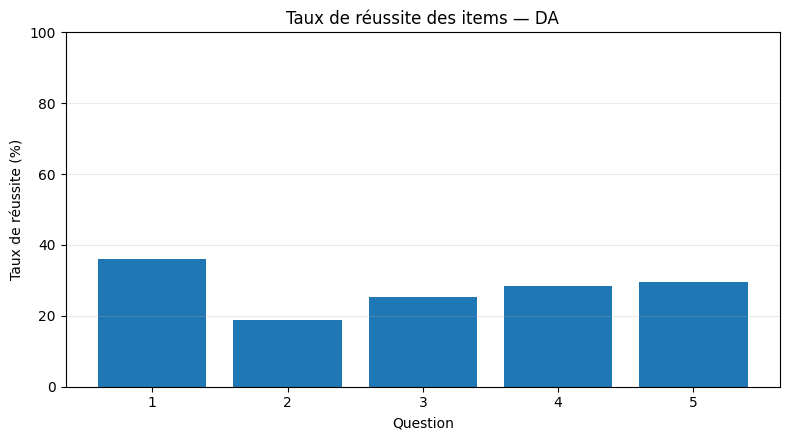

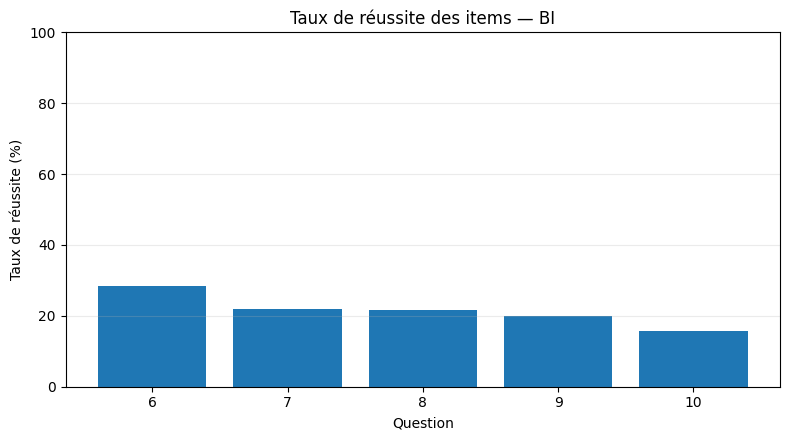

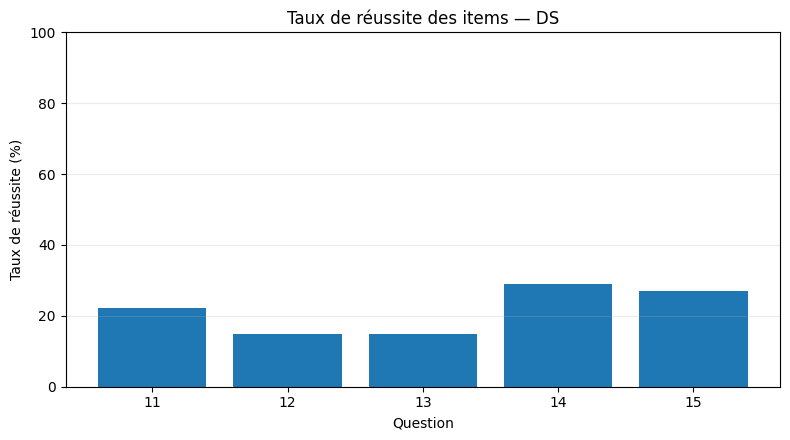

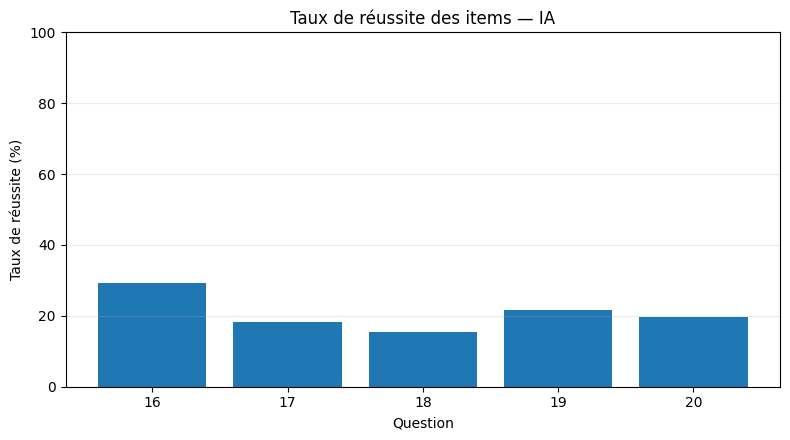

In [25]:
# ============================================================
# CELLULE 20 — Figures par item
# ============================================================

for domaine in [
    "DA",
    "BI",
    "DS",
    "IA"
]:

    temp = (

        stats_items[
            stats_items[
                "DOMAINE"
            ] == domaine
        ]

        .copy()

    )


    fig, ax = plt.subplots(
        figsize=(8, 4.5)
    )


    ax.bar(

        temp[
            "Q_NUM"
        ].astype(str),

        temp[
            "TAUX_REUSSITE"
        ]

    )


    ax.set_title(
        f"Taux de réussite des items — {domaine}"
    )

    ax.set_xlabel(
        "Question"
    )

    ax.set_ylabel(
        "Taux de réussite (%)"
    )

    ax.set_ylim(
        0,
        100
    )

    ax.grid(
        axis="y",
        alpha=0.25
    )


    fig.tight_layout()


    fig.savefig(

        FIGURE_DIR
        / f"taux_reussite_{domaine}.png",

        dpi=200,

        bbox_inches="tight"

    )


    plt.show()

#  Cellule 21 — Corrélations descriptives entre domaines
On utilise ici Spearman car les scores T0 ont seulement six valeurs possibles et sont donc très discrets.

In [26]:
# ============================================================
# CELLULE 21 — Corrélations
# ============================================================

correlations_scores = (

    scores_wide[
        [
            "S_DA",
            "S_BI",
            "S_DS",
            "S_IA"
        ]
    ]

    .corr(
        method="spearman"
    )

)


display(
    correlations_scores
)

,S_DA,S_BI,S_DS,S_IA
S_DA,1.000000,0.396177,0.407464,0.342357
S_BI,0.396177,1.000000,0.460334,0.522998
S_DS,0.407464,0.460334,1.000000,0.521676
S_IA,0.342357,0.522998,0.521676,1.000000


#  Cellule 22 — Contrôles scientifiques finaux

In [27]:
# ============================================================
# CELLULE 22 — Contrôles finaux
# ============================================================

assert (
    len(scores_wide)
    == len(t0)
)


assert (
    scores_wide[
        COL_ID
    ]
    .nunique()
    == len(t0)
)


assert (
    len(long_t0)
    == len(t0) * 20
)


for score in [

    "S_DA",
    "S_BI",
    "S_DS",
    "S_IA"

]:

    assert set(

        scores_wide[
            score
        ]
        .dropna()
        .unique()

    ).issubset({

        0,
        20,
        40,
        60,
        80,
        100

    })


# Interdiction volontaire d'un score global
assert (
    "SCORE_GLOBAL"
    not in diagnostic_t0.columns
)


assert (
    "S_GLOBAL"
    not in diagnostic_t0.columns
)


print(
    "✅ Contrôles scientifiques validés"
)

print(
    "Apprenants :",
    len(diagnostic_t0)
)

print(
    "Scores / apprenant : 4"
)

print(
    "Items / apprenant : 20"
)

✅ Contrôles scientifiques validés
Apprenants : 305
Scores / apprenant : 4
Items / apprenant : 20


# Cellule 23 — Exports

In [28]:
# ============================================================
# CELLULE 23 — Exports finaux du diagnostic T0
# ============================================================

# ------------------------------------------------------------
# Sécurité : reconstruire la distribution des scores si besoin
# ------------------------------------------------------------

if "distribution_scores" not in globals():

    distribution_scores_list = []

    for col in [
        "S_DA",
        "S_BI",
        "S_DS",
        "S_IA"
    ]:

        temp = (
            scores_wide[col]
            .value_counts()
            .reindex(
                [0, 20, 40, 60, 80, 100],
                fill_value=0
            )
            .rename("N")
            .reset_index()
            .rename(
                columns={
                    col: "SCORE"
                }
            )
        )

        temp["DOMAINE"] = (
            col.replace(
                "S_",
                ""
            )
        )

        temp["POURCENTAGE"] = (
            temp["N"]
            / len(scores_wide)
            * 100
        )

        distribution_scores_list.append(
            temp
        )


    distribution_scores = pd.concat(
        distribution_scores_list,
        ignore_index=True
    )


# ------------------------------------------------------------
# Sécurité : reconstruire le résumé si la Cellule 13C
# n'a pas été exécutée
# ------------------------------------------------------------

if "resume_scores" not in globals():

    resume_scores_list = []

    for col in [
        "S_DA",
        "S_BI",
        "S_DS",
        "S_IA"
    ]:

        resume_scores_list.append({

            "DOMAINE":
                col.replace(
                    "S_",
                    ""
                ),

            "N":
                len(scores_wide),

            "MOYENNE":
                scores_wide[col].mean(),

            "MEDIANE":
                scores_wide[col].median(),

            "ECART_TYPE":
                scores_wide[col].std(),

            "N_SCORE_0":
                (scores_wide[col] == 0).sum(),

            "PCT_SCORE_0":
                (scores_wide[col] == 0).mean() * 100,

            "N_SCORE_100":
                (scores_wide[col] == 100).sum(),

            "PCT_SCORE_100":
                (scores_wide[col] == 100).mean() * 100,

            "N_SCORE_GE_60":
                (scores_wide[col] >= 60).sum(),

            "PCT_SCORE_GE_60":
                (scores_wide[col] >= 60).mean() * 100
        })


    resume_scores = pd.DataFrame(
        resume_scores_list
    )


# ------------------------------------------------------------
# Préparer les statistiques descriptives proprement
# ------------------------------------------------------------

stats_scores_export = (
    stats_scores
    .reset_index()
    .rename(
        columns={
            "index": "SCORE_DOMAINE"
        }
    )
)


correlations_export = (
    correlations_scores
    .reset_index()
    .rename(
        columns={
            "index": "SCORE_DOMAINE"
        }
    )
)


# ------------------------------------------------------------
# Fichiers à exporter
# ------------------------------------------------------------

exports = {

    "corrige_T0_utilise.csv":
        corrige,

    "inventaire_modalites_T0.csv":
        inventaire_modalites,

    "T0_scoring_long.csv":
        long_t0,

    "T0_scores_domaines_long.csv":
        scores_long,

    "T0_scores_domaines.csv":
        scores_wide,

    "T0_statistiques_scores.csv":
        stats_scores_export,

    "T0_distribution_scores.csv":
        distribution_scores,

    "T0_resume_scores.csv":
        resume_scores,

    "T0_statistiques_items.csv":
        stats_items,

    "T0_diagnostic_par_domaine.csv":
        diagnostic_domaines,
        
    "T0_fiabilite_KR20.csv":
    KR20_T0,    

    "diagnostic_initial_T0.csv":
        diagnostic_t0,

    "correlations_scores_T0.csv":
        correlations_export
}


# ------------------------------------------------------------
# Export
# ------------------------------------------------------------

for nom, df in exports.items():

    chemin = (
        OUTPUT_DIR
        / nom
    )

    df.to_csv(
        chemin,
        index=False,
        encoding="utf-8-sig"
    )

    print(
        "✅",
        nom,
        "→",
        df.shape
    )


print(
    "\n✅ Tous les exports du Notebook 02 sont terminés."
)

print(
    "Dossier :",
    OUTPUT_DIR
)

✅ corrige_T0_utilise.csv → (20, 9)
✅ inventaire_modalites_T0.csv → (20, 5)
✅ T0_scoring_long.csv → (6100, 15)
✅ T0_scores_domaines_long.csv → (1220, 7)
✅ T0_scores_domaines.csv → (305, 5)
✅ T0_statistiques_scores.csv → (4, 9)
✅ T0_distribution_scores.csv → (24, 4)
✅ T0_resume_scores.csv → (4, 11)
✅ T0_statistiques_items.csv → (20, 9)
✅ T0_diagnostic_par_domaine.csv → (1220, 4)
✅ T0_fiabilite_KR20.csv → (4, 4)
✅ diagnostic_initial_T0.csv → (305, 24)
✅ correlations_scores_T0.csv → (4, 5)

✅ Tous les exports du Notebook 02 sont terminés.
Dossier : /home/andrycomputer/Documents/Model-eval-pers-elearning/outputs/02_diagnostic_T0


In [29]:
# ============================================================
# CELLULE 23B — Vérification des exports
# ============================================================

fichiers_attendus = [

    "corrige_T0_utilise.csv",
    "inventaire_modalites_T0.csv",
    "T0_scoring_long.csv",
    "T0_scores_domaines_long.csv",
    "T0_scores_domaines.csv",
    "T0_statistiques_scores.csv",
    "T0_distribution_scores.csv",
    "T0_resume_scores.csv",
    "T0_statistiques_items.csv",
    "T0_diagnostic_par_domaine.csv",
    "diagnostic_initial_T0.csv",
    "correlations_scores_T0.csv"

]


controle_exports = []


for nom in fichiers_attendus:

    chemin = (
        OUTPUT_DIR
        / nom
    )

    controle_exports.append({

        "FICHIER":
            nom,

        "EXISTE":
            chemin.exists(),

        "TAILLE_KO":
            round(
                chemin.stat().st_size / 1024,
                2
            )
            if chemin.exists()
            else np.nan

    })


controle_exports = pd.DataFrame(
    controle_exports
)


display(
    controle_exports
)


if not controle_exports["EXISTE"].all():

    raise FileNotFoundError(
        "Certains exports sont absents."
    )


print(
    "✅ Tous les fichiers attendus sont présents."
)

,FICHIER,EXISTE,TAILLE_KO
0,corrige_T0_utilise.csv,True,6.00
1,inventaire_modalites_T0.csv,True,3.58
2,T0_scoring_long.csv,True,1111.83
3,T0_scores_domaines_long.csv,True,38.92
4,T0_scores_domaines.csv,True,9.39
5,T0_statistiques_scores.csv,True,0.33
6,T0_distribution_scores.csv,True,0.68
7,T0_resume_scores.csv,True,0.56
8,T0_statistiques_items.csv,True,1.51
9,T0_diagnostic_par_domaine.csv,True,213.26


✅ Tous les fichiers attendus sont présents.


# Cellule 24 — Synthèse du notebook

In [30]:
# ============================================================
# CELLULE 24 — Synthèse JSON
# ============================================================

synthese = {

    "n_apprenants":
        int(
            len(t0)
        ),

    "n_questions":
        20,

    "domaines": {

        "DA":
            [1, 2, 3, 4, 5],

        "BI":
            [6, 7, 8, 9, 10],

        "DS":
            [11, 12, 13, 14, 15],

        "IA":
            [16, 17, 18, 19, 20]

    },

    "score": {

        "formule":
            "nombre correct / 5 * 100",

        "valeurs":
            [
                0,
                20,
                40,
                60,
                80,
                100
            ]

    },

    "score_global":
        False,

    "niveau_DIA":
        False,

    "recommandation_parcours":
        False,

    "corrige":
        CORRIGE_VALIDE.name,

    "interpretation":
        "indicateur diagnostique grossier car 5 items par domaine"

}


with open(

    OUTPUT_DIR
    / "synthese_02_diagnostic_T0.json",

    "w",

    encoding="utf-8"

) as f:

    json.dump(

        synthese,

        f,

        ensure_ascii=False,

        indent=4

    )


print(
    json.dumps(
        synthese,
        ensure_ascii=False,
        indent=4
    )
)


print(
    "\n✅ NOTEBOOK 02 TERMINÉ"
)

{
    "n_apprenants": 305,
    "n_questions": 20,
    "domaines": {
        "DA": [
            1,
            2,
            3,
            4,
            5
        ],
        "BI": [
            6,
            7,
            8,
            9,
            10
        ],
        "DS": [
            11,
            12,
            13,
            14,
            15
        ],
        "IA": [
            16,
            17,
            18,
            19,
            20
        ]
    },
    "score": {
        "formule": "nombre correct / 5 * 100",
        "valeurs": [
            0,
            20,
            40,
            60,
            80,
            100
        ]
    },
    "score_global": false,
    "niveau_DIA": false,
    "recommandation_parcours": false,
    "corrige": "corrige_T0_valide.csv",
    "interpretation": "indicateur diagnostique grossier car 5 items par domaine"
}

✅ NOTEBOOK 02 TERMINÉ
